# Evaluating the Effectiveness of Mixed Corruption-Based Data Augmentation on Lightweight CNN Robustness for Traffic Sign Recognition

**Course:** Deep Learning (ARTI 502)
**Institution:** Department of Computer Science, College of Computer Science and Information Technology, Imam Abdulrahman Bin Faisal University
**Date:** [Nov 20th, 2026]

**Team members**

| # | Member Name | Academic ID |
|---|---|---|
| 1 |Reena Aloraini |2220002781 |
| 2 |Maria Aljafri  |2230009064 |
| 3 |Wala Almukhtar |2230003613 |
| 4 |Rawan Alzaid   |2230003194 |
| 5 |Dima Alrahal   |2230009044 |
| 6 |Sara Alsahli   |2220003277 |  

---

## Overview

This notebook studies whether training with a **mix of Gaussian noise and Gaussian blur** makes a traffic sign classifier more robust than training with either corruption alone, and whether this costs accuracy on clean images. Two architectures are compared on the German Traffic Sign Recognition Benchmark (GTSRB): a small **custom CNN** trained from scratch and a **pretrained MobileNetV2**. The notebook runs top to bottom (Run All) and produces all tables and figures: dataset statistics, a learning-rate search, an input-resolution experiment, eight trained models, evaluation under five test conditions, confusion matrices, ROC curves and a final summary. Outputs are saved as CSV and PNG files.

**Research questions**
1. Does mixed corruption augmentation improve robustness to Gaussian noise and blur while preserving clean-image accuracy?
2. Do the two architectures show different robustness–accuracy trade-offs under the same augmentation strategies?

## Experimental design

| Component | Setup |
|---|---|
| **Dataset** | GTSRB, 43 classes, downloaded with torchvision.datasets.GTSRB |
| **Data split** | Train/test as provided by the dataset. 20 % of the training set is held out for validation, stratified and **track-disjoint** (frames of the same physical sign never appear in both parts, when track ids are available). The test set is used only for the final evaluation, never for model selection |
| **Preprocessing** | RGB, resized to 96 × 96, ImageNet mean/std normalization for both models |
| **Models** | **Custom CNN:** 3 × (Conv – BatchNorm – ReLU – MaxPool) with 32/64/128 channels, adaptive pooling, dropout, fully connected head. **MobileNetV2:** ImageNet weights, new 43-class classifier, whole network fine-tuned |
| **Training configurations** | **Clean** (no corruption), **Noise** (50 % of images get Gaussian noise), **Blur** (50 % get Gaussian blur), **Mixed** (50 % clean, 25 % noise, 25 % blur, mutually exclusive). Corruptions are applied to the training set only, before normalization |
| **Training procedure** | AdamW, cross-entropy loss, batch size 64, up to 15 epochs, early stopping (patience 5) and checkpoint selection on validation macro-F1, mixed precision on GPU, fixed random seed. Within each architecture all four configurations use the same split and settings |
| **Hyperparameters** | Custom CNN: learning rate chosen from {1e-3, 3e-4, 1e-4} on validation accuracy. MobileNetV2: 3e-4 for the classifier and 3e-5 for the backbone (set in advance, not tuned) |
| **Input-resolution experiment** | Custom CNN at 96 × 96 vs. 64 × 64, compared on validation accuracy, training time and input size. This is input-resolution reduction, not conventional feature selection or RFE |
| **Test conditions** | Five fixed, deterministic conditions applied to the test set before normalization and identical for every model: clean; Gaussian noise σ = 0.05 (mild) and σ = 0.10 (moderate); Gaussian blur kernel 3, σ = 0.5 (mild) and kernel 5, σ = 1.5 (moderate). These severities are proposed experimental settings, not an established benchmark |
| **Metrics** | Accuracy, macro precision, macro recall, macro F1, weighted F1; accuracy drop (clean − corrupted, in percentage points); mean corrupted accuracy; robustness improvement (vs. the clean-trained model of the same architecture); clean accuracy cost; confusion matrices; macro one-vs-rest and micro ROC-AUC for the best model of each architecture, selected on validation data |

**Conventions:** accuracies and F1 scores are in %, differences are in percentage points (pp). Results come from a single training run (one seed) per configuration.

**Outputs:** results/ (tables, figures, training histories) and checkpoints/ (best model of each run).

## 1. Imports and setting up the enviroment

In [ ]:
import json, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from PIL import Image
from IPython.display import display
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, models
import torchvision.transforms.v2 as T
import torchvision.transforms.v2.functional as TF
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score, roc_curve, auc)
from sklearn.preprocessing import label_binarize

# enviromennt settings 
SEED, NUM_CLASSES, IMG_SIZE, BATCH_SIZE = 42, 43, 96, 64
EPOCHS, PATIENCE = 15, 5  # up to 15 epochs, early stopping on validation macro-F1
WEIGHT_DECAY = 1e-4
SEARCH_LRS, SEARCH_EPOCHS = [1e-3, 3e-4, 1e-4], 8      # learning-rate search (custom CNN, clean data)
MBV2_HEAD_LR, MBV2_BACKBONE_LR = 3e-4, 3e-5            # initial MobileNetV2 settings (not tuned)

NOISE_STD_RANGE, BLUR_KERNEL, BLUR_SIGMA_RANGE = (0.02, 0.10), 5, (0.3, 1.5)   # training corruption strength
AUG_PROBS = {"Clean": (0.0, 0.0), "Noise": (0.5, 0.0), "Blur": (0.0, 0.5), "Mixed": (0.25, 0.25)}  # (p_noise, p_blur)
TEST_CONDITIONS = {"Clean": None, "Noise-Mild": ("noise", 0.05), "Noise-Moderate": ("noise", 0.10),
                   "Blur-Mild": ("blur", 3, 0.5), "Blur-Moderate": ("blur", 5, 1.5)}   # ("blur", kernel, sigma)
CORRUPTED = [c for c in TEST_CONDITIONS if c != "Clean"]

RUN_ID = "v2"   ## this notebook went through many runs    

ARCHS, AUGS = ["custom_cnn", "mobilenetv2"], list(AUG_PROBS)
LABEL = {"custom_cnn": "Custom CNN", "mobilenetv2": "MobileNetV2"}
COLORS = dict(zip(AUGS, plt.cm.tab10.colors))

## colab settings
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/DL_Project")
    DATA_DIR = Path("/content/data")            
except ImportError:
    ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
    DATA_DIR = ROOT / "data"
CKPT_DIR, RES_DIR = ROOT / "checkpoints", ROOT / "results"
for d in (DATA_DIR, CKPT_DIR, RES_DIR / "figures", RES_DIR / "tables", RES_DIR / "histories"):
    d.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"              
print("device:", device, "| AMP:", use_amp, "| torch", torch.__version__)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
set_seed(SEED)

def save_fig(fig, name):
    fig.tight_layout(); fig.savefig(RES_DIR / "figures" / f"{name}.png", dpi=300, bbox_inches="tight"); plt.show()

def save_table(df, name):
    df.to_csv(RES_DIR / "tables" / f"{name}.csv", index=False); display(df)

Mounted at /content/drive
device: cuda | AMP: True | torch 2.14.1+cu130


## 2. Dataset Loading and Statistical Analysis

GTSRB is downloaded with torchvision. 

100%|██████████| 187M/187M [00:21<00:00, 8.57MB/s]
100%|██████████| 89.0M/89.0M [00:10<00:00, 8.33MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 210kB/s]


Validation split: track-disjoint + stratified (split seed 48)


Reading image sizes:   0%|          | 0/26640 [00:00<?, ?it/s]

Reading image sizes:   0%|          | 0/12630 [00:00<?, ?it/s]

,Quantity,Value
0,Total images (train + test),39270
1,Number of classes,43
2,Training images (before split),26640
3,training split,21330
4,validation split,5310
5,Test images,12630
6,Training images per class (min / max),150 / 1500
7,Validation split method,track-disjoint + stratified (split seed 48)


,Set,Dimension,Min,Max,Mean,Median,Std
0,Train,Width (px),25,243,50.93,43.0,24.37
1,Train,Height (px),25,225,50.37,43.0,23.16
2,Test,Width (px),25,266,50.51,43.0,25.09
3,Test,Height (px),25,232,50.36,43.0,23.70
4,All images,Width (px),25,266,50.80,43.0,24.61
5,All images,Height (px),25,232,50.36,43.0,23.34


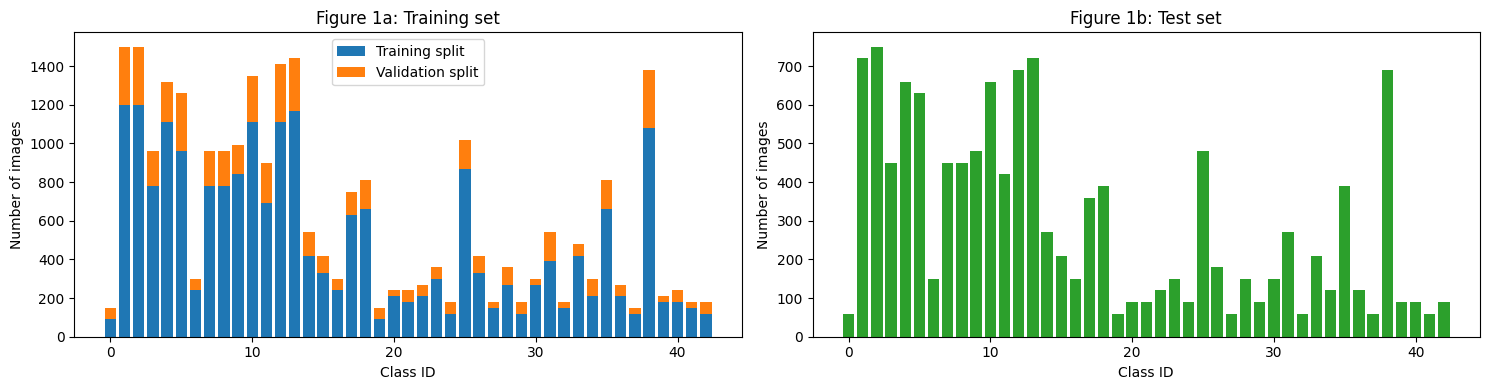

In [ ]:
train_ds = datasets.GTSRB(str(DATA_DIR), split="train", download=True)
test_ds = datasets.GTSRB(str(DATA_DIR), split="test", download=True)
train_paths, test_paths = [p for p, _ in train_ds._samples], [p for p, _ in test_ds._samples]
y_train_all = np.array([l for _, l in train_ds._samples])
y_test_all = np.array([l for _, l in test_ds._samples])
assert len(set(y_train_all)) == len(set(y_test_all)) == NUM_CLASSES

has_tracks = all(Path(p).stem.count("_") == 1 for p in train_paths)
groups = np.array([f"{l}_{Path(p).stem.split('_')[0]}" for p, l in train_ds._samples])   # (class, track)
covers_all = lambda idx: len(set(y_train_all[idx])) == NUM_CLASSES

fit_idx = val_idx = None
if has_tracks:
    for s in range(30):    # rare classes have few tracks: try several seeds until every class is in both splits
        sp = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + s)
        fi, vi = next(sp.split(np.zeros(len(y_train_all)), y_train_all, groups))
        if covers_all(fi) and covers_all(vi):
            assert set(groups[fi]).isdisjoint(groups[vi])
            fit_idx, val_idx, SPLIT = fi, vi, f"track-disjoint + stratified (split seed {SEED + s})"
            break
if fit_idx is None:
    fit_idx, val_idx = train_test_split(np.arange(len(y_train_all)), test_size=0.2, stratify=y_train_all, random_state=SEED)
    fit_idx, val_idx = np.sort(fit_idx), np.sort(val_idx)
    SPLIT = "stratified only (NOT track-disjoint: near-duplicate frames may be in both splits)"
assert len(set(fit_idx) & set(val_idx)) == 0 and covers_all(fit_idx) and covers_all(val_idx)
print("Validation split:", SPLIT)

def image_sizes(paths):     # reads only the file headers
    out = []
    for p in tqdm(paths, desc="Reading image sizes"):
        with Image.open(p) as im:
            out.append(im.size)
    return np.array(out)    # columns: width, height
sz_train, sz_test = image_sizes(train_paths), image_sizes(test_paths)

per_class = np.bincount(y_train_all, minlength=NUM_CLASSES)
save_table(pd.DataFrame({"Quantity": ["Total images (train + test)", "Number of classes", "Training images (before split)",
                                      "  training split", "  validation split", "Test images",
                                      "Training images per class (min / max)", "Validation split method"],
                         "Value": [len(train_paths) + len(test_paths), NUM_CLASSES, len(train_paths), len(fit_idx), len(val_idx),
                                   len(test_paths), f"{per_class.min()} / {per_class.max()}", SPLIT]}), "dataset_summary")

rows = []
for name, sz in [("Train", sz_train), ("Test", sz_test), ("All images", np.vstack([sz_train, sz_test]))]:
    for dim, c in (("Width (px)", 0), ("Height (px)", 1)):
        v = sz[:, c]
        rows.append({"Set": name, "Dimension": dim, "Min": v.min(), "Max": v.max(), "Mean": v.mean(), "Median": np.median(v), "Std": v.std(ddof=1)})
save_table(pd.DataFrame(rows).round(2), "image_size_statistics")

# Figure 1: class distribution 
cnt_fit, cnt_val = np.bincount(y_train_all[fit_idx], minlength=NUM_CLASSES), np.bincount(y_train_all[val_idx], minlength=NUM_CLASSES)
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].bar(range(NUM_CLASSES), cnt_fit, label="Training split"); ax[0].bar(range(NUM_CLASSES), cnt_val, bottom=cnt_fit, label="Validation split")
ax[0].set_title("Figure 1a: Training set"); ax[0].legend()
ax[1].bar(range(NUM_CLASSES), np.bincount(y_test_all, minlength=NUM_CLASSES), color="tab:green"); ax[1].set_title("Figure 1b: Test set")
for a in ax: a.set_xlabel("Class ID"); a.set_ylabel("Number of images")
save_fig(fig, "fig01_class_distribution")

Loading fit:   0%|          | 0/21330 [00:00<?, ?it/s]

Loading val:   0%|          | 0/5310 [00:00<?, ?it/s]

Loading test:   0%|          | 0/12630 [00:00<?, ?it/s]

train images: per-channel mean [0.345 0.316 0.325] std [0.278 0.265 0.271] | ImageNet mean (0.485, 0.456, 0.406) std (0.229, 0.224, 0.225)


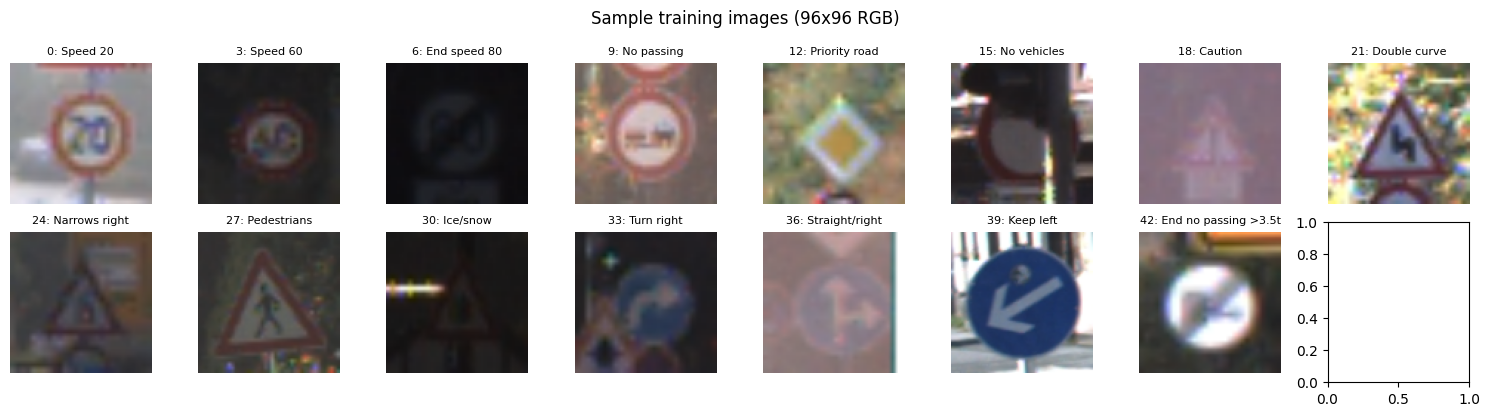

In [ ]:
CLASS_NAMES = ["Speed 20", "Speed 30", "Speed 50", "Speed 60", "Speed 70", "Speed 80", "End speed 80", "Speed 100", "Speed 120",
               "No passing", "No passing >3.5t", "Right-of-way", "Priority road", "Yield", "Stop", "No vehicles", "No >3.5t",
               "No entry", "Caution", "Curve left", "Curve right", "Double curve", "Bumpy road", "Slippery road", "Narrows right",
               "Road work", "Traffic signals", "Pedestrians", "Children", "Bicycles", "Ice/snow", "Wild animals", "End all limits",
               "Turn right", "Turn left", "Ahead only", "Straight/right", "Straight/left", "Keep right", "Keep left", "Roundabout",
               "End no passing", "End no passing >3.5t"]
assert len(CLASS_NAMES) == NUM_CLASSES

def load_u8(name, ds, idx, labels):
    # decode -> RGB -> 96x96 -> uint8 tensor (N,3,H,W); 
    f = DATA_DIR / f"cache_{name}_{IMG_SIZE}.pt"
    if f.exists():
        d = torch.load(f)
        if torch.equal(d["idx"], torch.as_tensor(idx)):
            return d["x"], d["y"]
    x = torch.stack([torch.from_numpy(np.asarray(ds[int(i)][0].convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)).copy()).permute(2, 0, 1)
                     for i in tqdm(idx, desc=f"Loading {name}")])
    y = torch.as_tensor(labels[idx])
    torch.save({"x": x, "y": y, "idx": torch.as_tensor(idx)}, f)
    return x, y

x_fit, y_fit = load_u8("fit", train_ds, fit_idx, y_train_all)
x_val, y_val = load_u8("val", train_ds, val_idx, y_train_all)
X_TEST, Y_TEST = load_u8("test", test_ds, np.arange(len(test_paths)), y_test_all)
DATA = {IMG_SIZE: {"train": (x_fit, y_fit), "val": (x_val, y_val)}}

for x, y in [(x_fit, y_fit), (x_val, y_val), (X_TEST, Y_TEST)]:  # quick check
    assert x.dtype == torch.uint8 and x.shape[1:] == (3, IMG_SIZE, IMG_SIZE) and len(x) == len(y) and 0 <= y.min() and y.max() < NUM_CLASSES
assert torch.equal(y_fit, torch.as_tensor(y_train_all[fit_idx])) and torch.equal(Y_TEST, torch.as_tensor(y_test_all))
print("train images: per-channel mean", (x_fit.float() / 255).mean((0, 2, 3)).numpy().round(3), "std", (x_fit.float() / 255).std((0, 2, 3)).numpy().round(3),
      "| ImageNet mean (0.485, 0.456, 0.406) std (0.229, 0.224, 0.225)")

# sample images with their labels (visual check that images and labels match)
fig, ax = plt.subplots(2, 8, figsize=(15, 4.2))
for a, c in zip(ax.ravel(), range(0, NUM_CLASSES, 3)):
    a.imshow(x_fit[int((y_fit == c).nonzero()[0][0])].permute(1, 2, 0).numpy()); a.axis("off"); a.set_title(f"{c}: {CLASS_NAMES[c]}", fontsize=8)
fig.suptitle("Sample training images (96x96 RGB)")
save_fig(fig, "fig01c_sample_images")

## 3. Preprocessing and Augmentation

Training pipeline: uint8 -> [0,1] -> optional corruption -> ImageNet mean/std normalization. Corruptions are always applied before normalization and only to the training set. Each image gets one mutually exclusive choice: noise (p_noise), blur (p_blur) or clean (the rest).

The five test conditions are generated once and the same tensors are used for every model (the same noise field is used for both noise levels). The corrupted images are rounded to 8 bit.

Building corrupted test sets:   0%|          | 0/25 [00:00<?, ?it/s]

Clean: fraction of images altered 0.00 (expected 0.00)
Noise: fraction of images altered 0.52 (expected 0.50)
Blur: fraction of images altered 0.51 (expected 0.50)
Mixed: fraction of images altered 0.55 (expected 0.50)


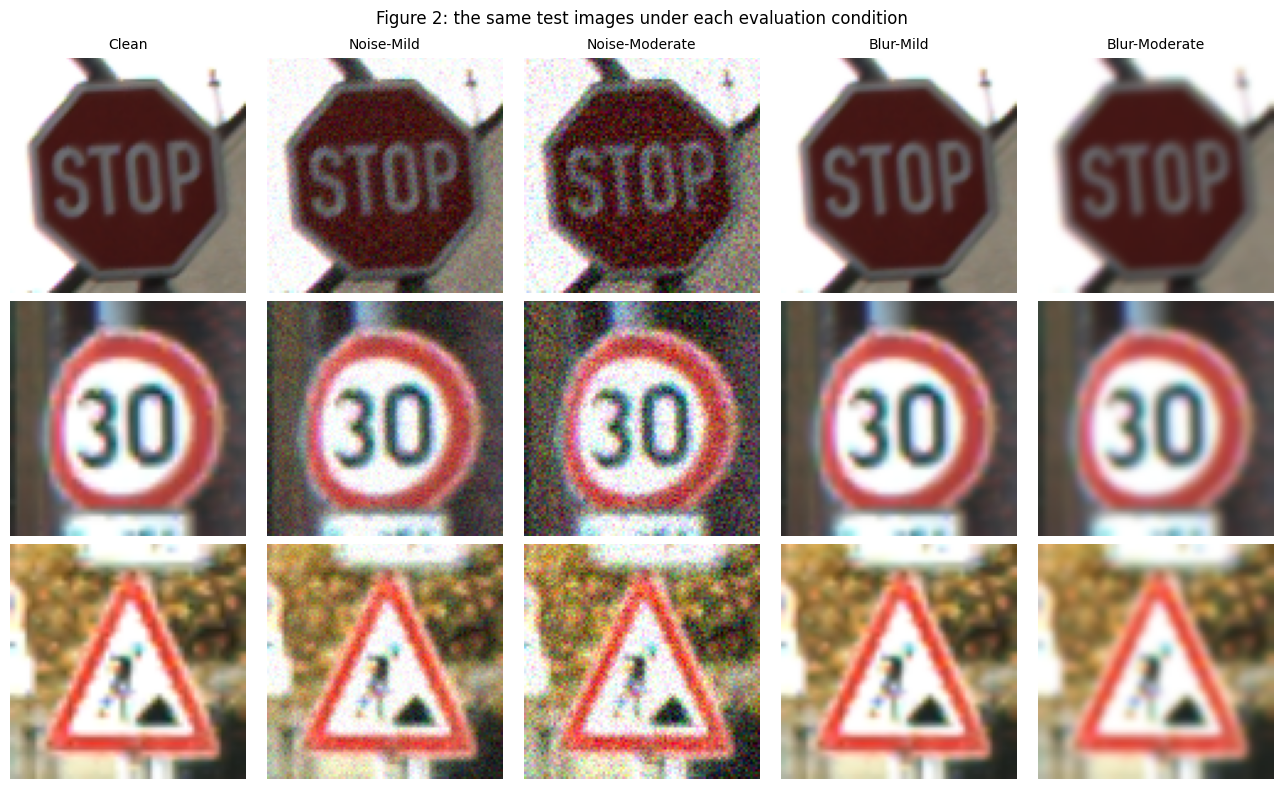

In [ ]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class AddGaussianNoise(nn.Module):
    def __init__(self, std_range):
        super().__init__(); self.std_range = std_range

    def forward(self, x):    # x in [0,1]
        s = torch.empty(1).uniform_(*self.std_range).item()
        return (x + torch.randn_like(x) * s).clamp(0, 1)

def make_augment(aug):
    p_noise, p_blur = AUG_PROBS[aug]
    noise, blur = AddGaussianNoise(NOISE_STD_RANGE), T.GaussianBlur(BLUR_KERNEL, BLUR_SIGMA_RANGE)
    def augment(x):
        u = torch.rand(1).item() # one mutually exclusive choice per image
        if u < p_noise: return noise(x)
        if u < p_noise + p_blur: return blur(x)
        return x
    return augment

class TrainSet(Dataset): # used for training only
    def __init__(self, x_u8, y, aug):
        self.x, self.y, self.augment = x_u8, y, make_augment(aug)

    def __len__(self): return len(self.y)
    
    def __getitem__(self, i):
        img = self.augment(self.x[i].float() / 255)  # corruption before normalization
        return (img - MEAN) / STD, self.y[i]

def normalize(x_u8): # evaluation path: no augmentation at all
    return (x_u8.to(device).float() / 255 - MEAN.to(device)) / STD.to(device)

def build_test_sets(x_u8, chunk=512):
    g = torch.Generator().manual_seed(1234)
    out = {c: torch.empty_like(x_u8) for c in TEST_CONDITIONS}
    for i in tqdm(range(0, len(x_u8), chunk), desc="Building corrupted test sets"):
        x = x_u8[i:i + chunk].float() / 255
        z = torch.randn(x.shape, generator=g)  # shared N(0,1) field
        for c, spec in TEST_CONDITIONS.items():
            if spec is None: y = x
            elif spec[0] == "noise": y = x + spec[1] * z
            else: y = TF.gaussian_blur(x, kernel_size=[spec[1]] * 2, sigma=[spec[2]] * 2)
            out[c][i:i + chunk] = (y.clamp(0, 1) * 255).round().to(torch.uint8)
    return out

TEST = build_test_sets(X_TEST)
assert torch.equal(TEST["Clean"], X_TEST) and all(v.shape == X_TEST.shape for v in TEST.values())

#quick check
rand_img = torch.randint(0, 256, (3, IMG_SIZE, IMG_SIZE), dtype=torch.uint8)
for aug, (pn, pb) in AUG_PROBS.items():
    f = make_augment(aug)
    changed = np.mean([not torch.equal(f(rand_img.float() / 255), rand_img.float() / 255) for _ in range(300)])
    print(f"{aug}: fraction of images altered {changed:.2f} (expected {pn + pb:.2f})")

# Figure 2: clean and corrupted examples 
fig, ax = plt.subplots(3, 5, figsize=(13, 8))
for r, c in enumerate([14, 1, 25]):
    i = int((Y_TEST == c).nonzero()[0][0])
    for k, cond in enumerate(TEST_CONDITIONS):
        ax[r, k].imshow(TEST[cond][i].permute(1, 2, 0).numpy()); ax[r, k].axis("off")
        ax[r, k].set_title(cond if r == 0 else "", fontsize=10)
fig.suptitle("Figure 2: the same test images under each evaluation condition")
save_fig(fig, "fig02_corruption_examples")

## 4. Model Architectures
* **Custom CNN:** 3 x (Conv3x3 - BatchNorm - ReLU - MaxPool) with 32/64/128 channels, adaptive average pooling (4x4), Linear(2048, 256) - Dropout(0.4) - Linear(256, 43).
* **MobileNetV2:** torchvision ImageNet weights, new 43-class classifier. The weights are **verified** against the reference torchvision weights. The whole network is fine-tuned.

In [ ]:
class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()
        block = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 16, 256), nn.ReLU(inplace=True), nn.Dropout(0.4), nn.Linear(256, NUM_CLASSES))
    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

def build_model(arch):
    if arch == "custom_cnn":
        return CustomCNN()
    w = models.MobileNet_V2_Weights.IMAGENET1K_V1
    m = models.mobilenet_v2(weights=w)
    
    ref_weights = w.get_state_dict(progress=True)
    assert all(torch.equal(m.state_dict()[k], v) for k, v in ref_weights.items()), "pretrained weights were not loaded"
    assert np.allclose(w.transforms().mean, MEAN.flatten().numpy()) and np.allclose(w.transforms().std, STD.flatten().numpy())
    m.classifier[1] = nn.Linear(m.last_channel, NUM_CLASSES)
    return m

for a in ARCHS:
    m = build_model(a)
    print(f"{LABEL[a]}: total parameters = {sum(p.numel() for p in m.parameters()):,}")
print("MobileNetV2 pretrained ImageNet weights and normalization verified.")

Custom CNN: total parameters = 629,067
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 128MB/s]


MobileNetV2: total parameters = 2,278,955
MobileNetV2 pretrained ImageNet weights and normalization verified.


## 5. Training and Validation

* Loss: CrossEntropyLoss, optimizer: AdamW, mixed precision. Validation is always on clean validation images.
* Checkpoint selection and early stopping use validation macro-F1 (patience).

* **MobileNetV2:** the whole network is fine-tuned from the start (no frozen phase) with a small learning rate for the pretrained backbone (3e-5) and a larger one for the new classifier (3e-4); BatchNorm statistics are updated during training. 

In [ ]:
@torch.no_grad()
def predict_logits(model, x_u8, batch=256):
    model.eval()
    return torch.cat([model(normalize(x_u8[i:i + batch])).float().cpu() for i in range(0, len(x_u8), batch)])

def evaluate(model, x, y):                                 # loss, accuracy (%), macro-F1 (%)
    logits = predict_logits(model, x); pred = logits.argmax(1)
    return F.cross_entropy(logits, y).item(), (pred == y).float().mean().item() * 100, f1_score(y, pred, average="macro") * 100

def make_cfg(arch, aug, lr, epochs, size):                 # everything that affects the trained model
    cfg = dict(run_id=RUN_ID, arch=arch, aug=aug, probs=AUG_PROBS[aug], lr=lr, epochs=epochs, patience=PATIENCE, batch=BATCH_SIZE,
               weight_decay=WEIGHT_DECAY, size=size, seed=SEED, select="val_macro_f1", noise=NOISE_STD_RANGE,
               blur=(BLUR_KERNEL, BLUR_SIGMA_RANGE), n_train=len(DATA[size]["train"][1]), n_val=len(DATA[size]["val"][1]))
    if arch == "mobilenetv2":
        cfg.update(backbone_lr=MBV2_BACKBONE_LR, finetune="all layers, BN statistics updating, no frozen phase")
    return json.loads(json.dumps(cfg))

def load_ckpt(name, cfg):
    f = CKPT_DIR / f"{name}.pt"
    if not f.exists(): return None
    ck = torch.load(f, map_location="cpu")
    if ck["cfg"] != cfg:
        print(f"[{name}] checkpoint was trained with different settings -> retraining"); return None
    return ck

def train_model(name, arch, aug, lr, epochs, size=IMG_SIZE):
    cfg, hist_file = make_cfg(arch, aug, lr, epochs, size), RES_DIR / "histories" / f"{name}.csv"
    ck = load_ckpt(name, cfg)
    if ck is not None and hist_file.exists():
        print(f"[{name}] matching checkpoint found, skipping training"); return ck["info"], pd.read_csv(hist_file)

    (x, y), (xv, yv) = DATA[size]["train"], DATA[size]["val"]
    set_seed(SEED)
    model = build_model(arch).to(device)
    if arch == "mobilenetv2":    # whole network trained: small learning rate for the pretrained backbone, larger for the new classifier
        groups_ = [{"params": list(model.classifier.parameters()), "lr": lr},
                   {"params": list(model.features.parameters()), "lr": MBV2_BACKBONE_LR}]
    else:
        groups_ = [{"params": list(model.parameters()), "lr": lr}]
    opt = torch.optim.AdamW(groups_, weight_decay=WEIGHT_DECAY)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    loader = DataLoader(TrainSet(x, y, aug), batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=device.type == "cuda")

    hist, best_f1, best_state, bad, train_time = [], -1.0, None, 0, 0.0
    for ep in range(epochs):
        t0 = time.time()
        model.train()
        tl = tc = n = 0
        for xb, yb in tqdm(loader, desc=f"{name} epoch {ep + 1}/{epochs}", leave=False):
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out = model(xb); loss = F.cross_entropy(out, yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(yb); tc += (out.argmax(1) == yb).sum().item(); n += len(yb)
        vl, va, vf1 = evaluate(model, xv, yv)
        train_time += time.time() - t0
        hist.append(dict(epoch=ep + 1, train_loss=tl / n, train_acc=100 * tc / n, val_loss=vl, val_acc=va, val_macro_f1=vf1))
        print(f"{name} ep{ep + 1}: train loss {tl / n:.3f} acc {100 * tc / n:.1f} | val loss {vl:.3f} acc {va:.1f} F1 {vf1:.1f}")
        if vf1 > best_f1:
            best_f1, best_ep, bad = vf1, ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: print(f"{name}: early stopping"); break

    model.load_state_dict(best_state)
    h = pd.DataFrame(hist); h.to_csv(hist_file, index=False)
    info = dict(name=name, arch=arch, aug=aug, lr=lr, best_epoch=best_ep + 1, epochs_run=len(h), val_loss=float(h.val_loss[best_ep]),
                val_acc=float(h.val_acc[best_ep]), val_macro_f1=float(best_f1), train_time_s=train_time,
                total_params=sum(p.numel() for p in model.parameters()), trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad))
    torch.save({"model": best_state, "cfg": cfg, "info": info}, CKPT_DIR / f"{name}.pt")
    del model, opt; torch.cuda.empty_cache()
    return info, h

def load_model(name, cfg):
    ck = load_ckpt(name, cfg)
    assert ck is not None, f"no up-to-date checkpoint for {name}; run the training cells first"
    m = build_model(cfg["arch"]); m.load_state_dict(ck["model"])
    return m.to(device).eval()

## 6. Hyperparameter Optimization

Learning-rate search for the custom CNN on clean training data. The learning rate is chosen by validation accuracy (ties: macro-F1); the test set is not used. MobileNetV2 keeps the prescribed transfer-learning rates (3e-4 classifier, 3e-5 backbone) and is not tuned.

search_lr_0.001 epoch 1/8:   0%|          | 0/334 [00:00<?, ?it/s]

search_lr_0.001 ep1: train loss 2.038 acc 39.3 | val loss 1.613 acc 46.7 F1 33.4


search_lr_0.001 epoch 2/8:   0%|          | 0/334 [00:00<?, ?it/s]

search_lr_0.001 ep2: train loss 0.948 acc 68.7 | val loss 1.029 acc 69.1 F1 58.9


search_lr_0.001 epoch 3/8:   0%|          | 0/334 [00:00<?, ?it/s]

search_lr_0.001 ep3: train loss 0.432 acc 86.0 | val loss 0.737 acc 78.5 F1 68.8


... (40 outputs left out)

search_lr_0.0001 epoch 8/8:   0%|          | 0/334 [00:00<?, ?it/s]

search_lr_0.0001 ep8: train loss 0.313 acc 92.1 | val loss 0.760 acc 77.0 F1 66.2


,Learning rate,Val accuracy (%),Val loss,Val macro-F1 (%),Best epoch,Training time (s)
0,0.0010,85.9322,0.5493,83.1317,7,60.9890
1,0.0003,85.4237,0.5196,81.9544,8,59.9098
2,0.0001,76.9680,0.7603,66.1885,8,61.2689


Selected custom-CNN learning rate (validation only): 0.001


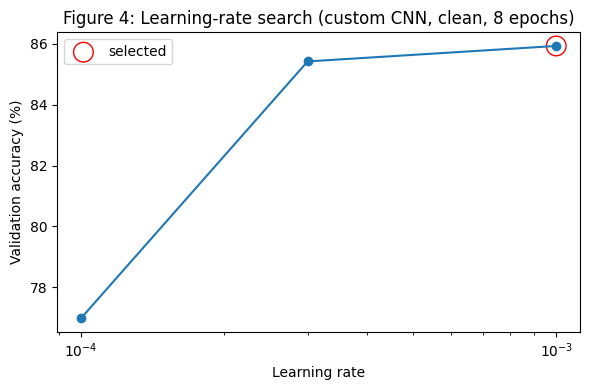

,Hyperparameter,Custom CNN,MobileNetV2
0,Optimizer,AdamW,AdamW
1,Learning rate,0.001 (selected on validation accuracy),0.0003 classifier / 3e-05 backbone (prescribed...
2,Weight decay,0.0001,0.0001
3,Batch size,64,64
4,Max epochs / early-stopping patience,15 / 5,15 / 5
5,Checkpoint selection,validation macro-F1,validation macro-F1
6,Input size,96x96,96x96
7,Frozen backbone epochs,-,0 (none)
8,Fine-tuned layers,all layers trained,all layers (BN statistics updated)
9,Dropout,0.4,0.2 (torchvision default)


In [7]:
search = {lr: train_model(f"search_lr_{lr:g}", "custom_cnn", "Clean", lr, SEARCH_EPOCHS)[0] for lr in SEARCH_LRS}
lr_df = pd.DataFrame([{"Learning rate": lr, "Val accuracy (%)": i["val_acc"], "Val loss": i["val_loss"], "Val macro-F1 (%)": i["val_macro_f1"],
                       "Best epoch": i["best_epoch"], "Training time (s)": i["train_time_s"]} for lr, i in search.items()])
save_table(lr_df.round(4), "lr_search")
best_lr = float(lr_df.sort_values(["Val accuracy (%)", "Val macro-F1 (%)"], ascending=False).iloc[0]["Learning rate"])
print("Selected custom-CNN learning rate (validation only):", best_lr)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(lr_df["Learning rate"], lr_df["Val accuracy (%)"], "o-")
ax.scatter([best_lr], [lr_df.set_index("Learning rate").loc[best_lr, "Val accuracy (%)"]], s=200, facecolors="none", edgecolors="red", label="selected")
ax.set_xscale("log"); ax.set_xlabel("Learning rate"); ax.set_ylabel("Validation accuracy (%)"); ax.legend()
ax.set_title(f"Figure 4: Learning-rate search (custom CNN, clean, {SEARCH_EPOCHS} epochs)")
save_fig(fig, "fig04_lr_search")

LR_MAIN = {"custom_cnn": best_lr, "mobilenetv2": MBV2_HEAD_LR}
save_table(pd.DataFrame({"Hyperparameter": ["Optimizer", "Learning rate", "Weight decay", "Batch size", "Max epochs / early-stopping patience",
                                            "Checkpoint selection", "Input size", "Frozen backbone epochs", "Fine-tuned layers", "Dropout", "Mixed precision", "Seed"],
                         "Custom CNN": ["AdamW", f"{best_lr:g} (selected on validation accuracy)", WEIGHT_DECAY, BATCH_SIZE, f"{EPOCHS} / {PATIENCE}",
                                        "validation macro-F1", "96x96", "-", "all layers trained", "0.4", use_amp, SEED],
                         "MobileNetV2": ["AdamW", f"{MBV2_HEAD_LR:g} classifier / {MBV2_BACKBONE_LR:g} backbone (prescribed, not tuned)", WEIGHT_DECAY, BATCH_SIZE,
                                         f"{EPOCHS} / {PATIENCE}", "validation macro-F1", "96x96", "0 (none)",
                                         "all layers (BN statistics updated)", "0.2 (torchvision default)", use_amp, SEED]}), "final_hyperparameters")

## 7. Input-Resolution Reduction Experiment

**input-resolution reduction:** It checks how much accuracy is lost when the number of input values per image is reduced from 3x96x96 to 3x64x64.

Custom CNN, clean data, selected learning rate, same settings and epochs as the learning-rate search. The 96x96 result is the search run for the selected learning rate (identical settings); the 64x64 images are the 96x96 images resized with antialiasing. Only validation data is used.

resolution_64 epoch 1/8:   0%|          | 0/334 [00:00<?, ?it/s]

resolution_64 ep1: train loss 1.870 acc 44.8 | val loss 1.209 acc 59.1 F1 47.6


resolution_64 epoch 2/8:   0%|          | 0/334 [00:00<?, ?it/s]

resolution_64 ep2: train loss 0.531 acc 83.1 | val loss 0.627 acc 82.1 F1 77.9


resolution_64 epoch 3/8:   0%|          | 0/334 [00:00<?, ?it/s]

resolution_64 ep3: train loss 0.215 acc 93.5 | val loss 0.434 acc 87.6 F1 81.8


... (7 outputs left out)

resolution_64 ep7: train loss 0.065 acc 98.0 | val loss 0.342 acc 91.4 F1 86.6


resolution_64 epoch 8/8:   0%|          | 0/334 [00:00<?, ?it/s]

resolution_64 ep8: train loss 0.045 acc 98.7 | val loss 0.334 acc 92.0 F1 90.1


,Input resolution,Input dimensionality,Val accuracy (%),Val macro-F1 (%),Training time (s)
0,96x96,27648,85.932,83.132,60.989
1,64x64,12288,91.996,90.127,34.431


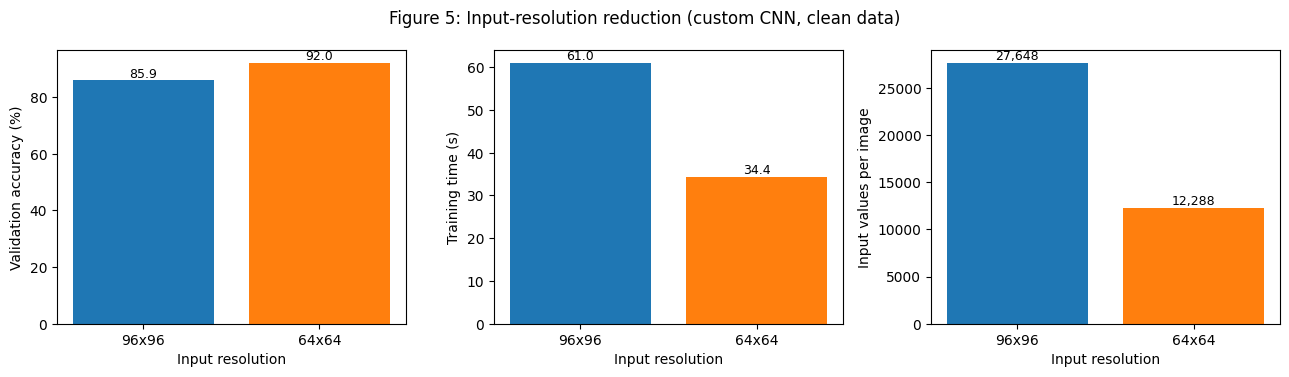

In [8]:
def resize_u8(x, size):
    return torch.cat([F.interpolate(x[i:i + 2048].float(), size=(size, size), mode="bilinear", antialias=True, align_corners=False)
                      .round().clamp(0, 255).to(torch.uint8) for i in range(0, len(x), 2048)])

DATA[64] = {"train": (resize_u8(x_fit, 64), y_fit), "val": (resize_u8(x_val, 64), y_val)}
res = {96: search[best_lr], 64: train_model("resolution_64", "custom_cnn", "Clean", best_lr, SEARCH_EPOCHS, size=64)[0]}
res_df = pd.DataFrame([{"Input resolution": f"{s}x{s}", "Input dimensionality": 3 * s * s, "Val accuracy (%)": i["val_acc"],
                        "Val macro-F1 (%)": i["val_macro_f1"], "Training time (s)": i["train_time_s"]} for s, i in res.items()])
save_table(res_df.round(3), "resolution_reduction")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, col, yl in zip(ax, ["Val accuracy (%)", "Training time (s)", "Input dimensionality"], ["Validation accuracy (%)", "Training time (s)", "Input values per image"]):
    a.bar(res_df["Input resolution"], res_df[col], color=["tab:blue", "tab:orange"]); a.set_ylabel(yl); a.set_xlabel("Input resolution")
    for k, v in enumerate(res_df[col]): a.text(k, v, f"{v:.1f}" if col != "Input dimensionality" else f"{v:,}", ha="center", va="bottom", fontsize=9)
fig.suptitle("Figure 5: Input-resolution reduction (custom CNN, clean data)")
save_fig(fig, "fig05_resolution_reduction")

## 8. Main Training Experiments

Eight runs (2 architectures x 4 configurations). Within an architecture, only the training corruption differs. Completed runs with unchanged settings are loaded instead of retrained.

custom_cnn_Clean epoch 1/15:   0%|          | 0/334 [00:00<?, ?it/s]

custom_cnn_Clean ep1: train loss 2.038 acc 39.3 | val loss 1.613 acc 46.7 F1 33.4


custom_cnn_Clean epoch 2/15:   0%|          | 0/334 [00:00<?, ?it/s]

custom_cnn_Clean ep2: train loss 0.948 acc 68.7 | val loss 1.029 acc 69.1 F1 58.9


custom_cnn_Clean epoch 3/15:   0%|          | 0/334 [00:00<?, ?it/s]

custom_cnn_Clean ep3: train loss 0.432 acc 86.0 | val loss 0.737 acc 78.5 F1 68.8


... (231 outputs left out)

mobilenetv2_Mixed ep14: train loss 0.012 acc 99.7 | val loss 0.222 acc 94.2 F1 92.9


mobilenetv2_Mixed epoch 15/15:   0%|          | 0/334 [00:00<?, ?it/s]

mobilenetv2_Mixed ep15: train loss 0.014 acc 99.6 | val loss 0.236 acc 93.7 F1 91.4


,Architecture,Config,Epochs run,Best epoch,Val acc (%),Val macro-F1 (%),Val loss,Training time (s)
0,Custom CNN,Clean,15,13,89.153,87.412,0.447,114.426
1,Custom CNN,Noise,15,14,87.684,82.950,0.518,157.987
2,Custom CNN,Blur,15,12,90.113,86.893,0.501,259.239
3,Custom CNN,Mixed,15,14,89.793,85.641,0.443,208.521
4,MobileNetV2,Clean,15,13,93.277,90.954,0.286,255.038
5,MobileNetV2,Noise,15,13,94.934,93.533,0.191,300.648
6,MobileNetV2,Blur,15,15,94.218,92.565,0.282,382.034
7,MobileNetV2,Mixed,15,14,94.162,92.885,0.222,349.752


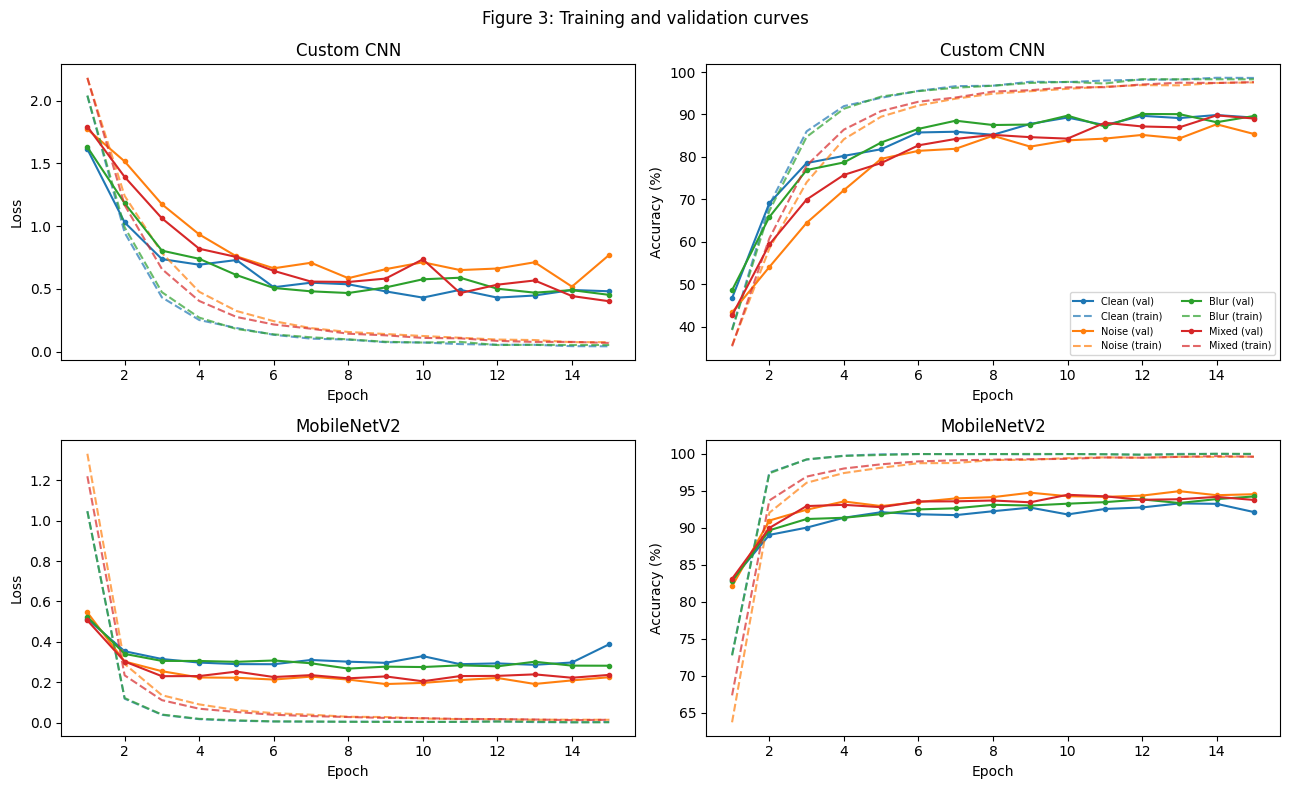

In [9]:
INFOS, HIST = {}, {}
for arch in ARCHS:
    for aug in AUGS:
        INFOS[(arch, aug)], HIST[(arch, aug)] = train_model(f"{arch}_{aug}", arch, aug, LR_MAIN[arch], EPOCHS)

rows = []
for (arch, aug), i in INFOS.items():
    h = HIST[(arch, aug)]
    rows.append({"Architecture": LABEL[arch], "Config": aug, "Epochs run": i["epochs_run"], "Best epoch": i["best_epoch"], "Val acc (%)": i["val_acc"],
                 "Val macro-F1 (%)": i["val_macro_f1"], "Val loss": i["val_loss"], "Training time (s)": i["train_time_s"]})
save_table(pd.DataFrame(rows).round(3), "training_summary")

# ---- Figure 3: training curves (dashed = training on augmented batches, solid = clean validation) ----
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for r, arch in enumerate(ARCHS):
    for aug in AUGS:
        h = HIST[(arch, aug)]
        for c, (tr, va) in enumerate([("train_loss", "val_loss"), ("train_acc", "val_acc")]):
            ax[r, c].plot(h.epoch, h[va], "-o", ms=3, color=COLORS[aug], label=f"{aug} (val)")
            ax[r, c].plot(h.epoch, h[tr], "--", color=COLORS[aug], alpha=0.7, label=f"{aug} (train)")
    for c, yl in enumerate(["Loss", "Accuracy (%)"]):
        ax[r, c].set_title(f"{LABEL[arch]}"); ax[r, c].set_xlabel("Epoch"); ax[r, c].set_ylabel(yl)
ax[0, 1].legend(fontsize=7, ncol=2)
fig.suptitle("Figure 3: Training and validation curves")
save_fig(fig, "fig03_training_curves")

## 9. Corruption-Based Evaluation

Every model is evaluated in eval() mode without gradients on the same five test conditions. 

In [10]:
def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    wf1 = precision_recall_fscore_support(y, p, average="weighted", zero_division=0)[2]
    return dict(accuracy=accuracy_score(y, p) * 100, macro_precision=pr * 100, macro_recall=rc * 100, macro_f1=f1 * 100, weighted_f1=wf1 * 100)

y_test = Y_TEST.numpy()
PREDS, rows = {}, []
for arch in ARCHS:
    for aug in AUGS:
        model = load_model(f"{arch}_{aug}", make_cfg(arch, aug, LR_MAIN[arch], EPOCHS, IMG_SIZE))
        for cond in TEST_CONDITIONS:
            PREDS[(arch, aug, cond)] = predict_logits(model, TEST[cond]).argmax(1).numpy()
            rows.append(dict(architecture=LABEL[arch], config=aug, condition=cond, **metrics(y_test, PREDS[(arch, aug, cond)]),
                             training_time_s=INFOS[(arch, aug)]["train_time_s"], total_params=INFOS[(arch, aug)]["total_params"]))
        del model; torch.cuda.empty_cache()
results = pd.DataFrame(rows)
clean_acc = results[results.condition == "Clean"].set_index(["architecture", "config"])["accuracy"]
results["accuracy_drop_pp"] = [clean_acc[(a, c)] - acc for a, c, acc in zip(results.architecture, results.config, results.accuracy)]   # clean - corrupted
results.to_csv(RES_DIR / "tables" / "all_results.csv", index=False)
display(results.round(2).head(10))

,architecture,config,condition,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,training_time_s,total_params,accuracy_drop_pp
0,Custom CNN,Clean,Clean,88.72,86.57,83.31,83.60,88.39,114.43,629067,0.00
1,Custom CNN,Clean,Noise-Mild,71.44,75.23,64.93,65.87,71.72,114.43,629067,17.28
2,Custom CNN,Clean,Noise-Moderate,50.15,63.95,44.88,45.82,50.95,114.43,629067,38.57
3,Custom CNN,Clean,Blur-Mild,88.51,85.73,83.02,83.22,88.16,114.43,629067,0.21
4,Custom CNN,Clean,Blur-Moderate,86.87,83.55,80.96,80.97,86.49,114.43,629067,1.84
5,Custom CNN,Noise,Clean,88.90,86.85,82.56,82.94,88.49,157.99,629067,0.00
6,Custom CNN,Noise,Noise-Mild,87.59,85.72,81.29,81.68,87.20,157.99,629067,1.31
7,Custom CNN,Noise,Noise-Moderate,84.41,82.31,78.37,78.35,83.98,157.99,629067,4.49
8,Custom CNN,Noise,Blur-Mild,88.59,85.85,82.04,82.30,88.14,157.99,629067,0.31
9,Custom CNN,Noise,Blur-Moderate,87.15,82.97,80.22,80.38,86.72,157.99,629067,1.75


## 10. Performance Metrics and Visualizations

* **accuracy drop** = clean accuracy - corrupted accuracy (positive = degradation).
* **mean corrupted accuracy** = mean over the 4 corrupted conditions. 
* **robustness improvement** = mean corrupted accuracy minus that of the clean-trained model of the same architecture. 
* **clean accuracy cost** = clean accuracy of the clean-trained model minus that of the augmented model (positive = clean accuracy lost).

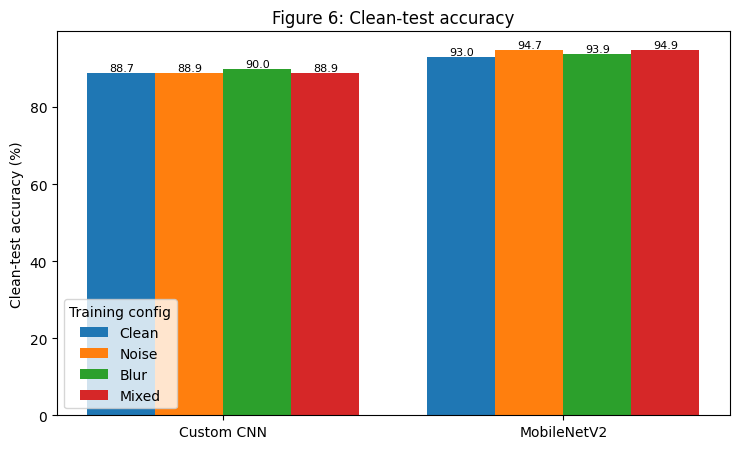

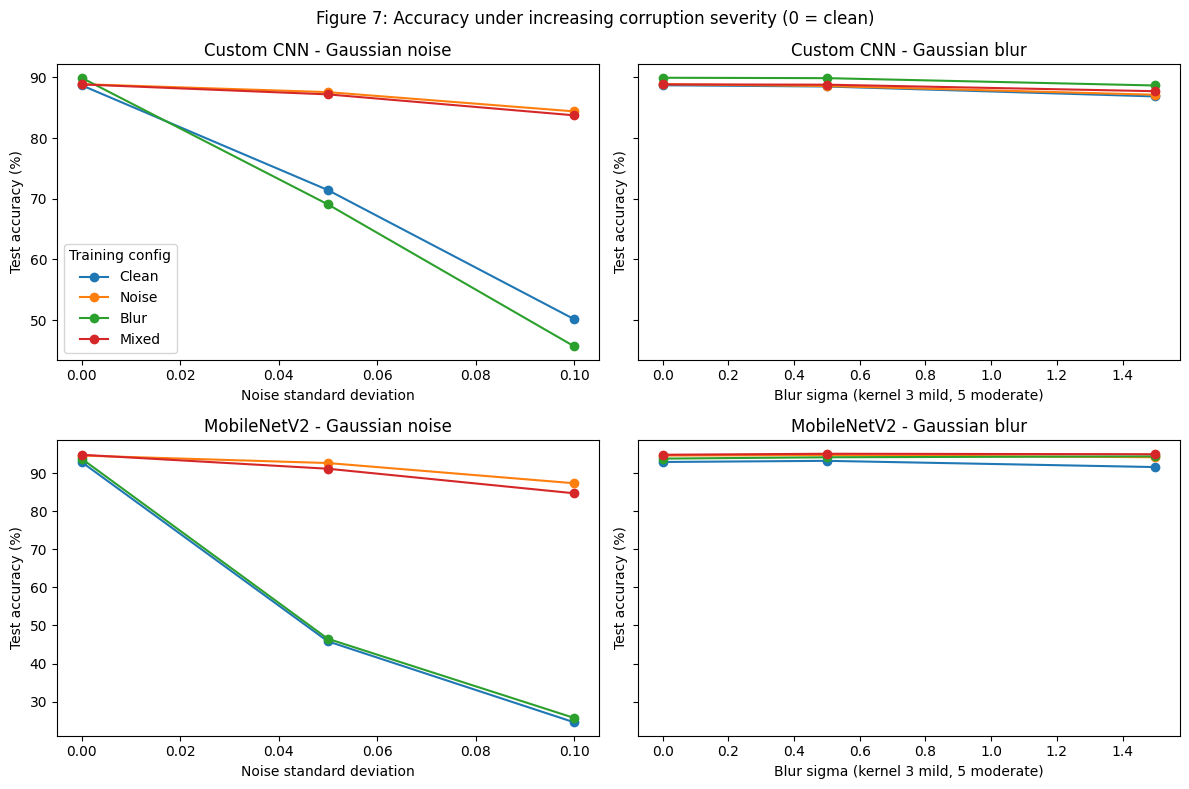

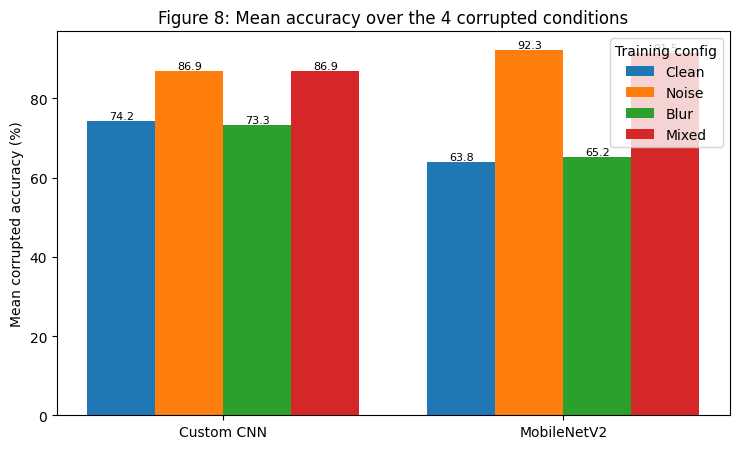

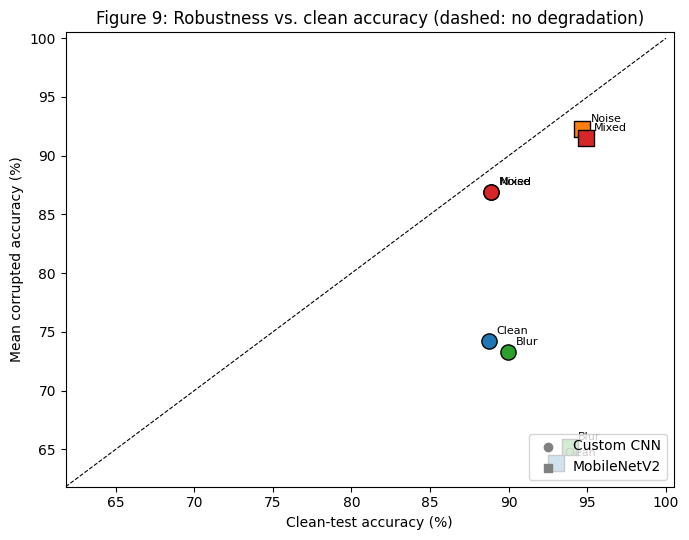

In [ ]:
acc = results.pivot_table(index=["architecture", "config"], columns="condition", values="accuracy")
summ = []
for arch in ARCHS:
    base_clean, base_corr = acc.loc[(LABEL[arch], "Clean"), "Clean"], acc.loc[(LABEL[arch], "Clean"), CORRUPTED].mean()
    for aug in AUGS:
        a = acc.loc[(LABEL[arch], aug)]
        r = results[(results.architecture == LABEL[arch]) & (results.config == aug) & (results.condition == "Clean")].iloc[0]
        summ.append({"Architecture": LABEL[arch], "Config": aug, "arch_key": arch, "Clean acc (%)": a["Clean"], "Mean corrupted acc (%)": a[CORRUPTED].mean(),
                     "Macro-F1 clean (%)": r.macro_f1, "Accuracy drop (pp)": a["Clean"] - a[CORRUPTED].mean(),
                     "Robustness improvement (pp)": a[CORRUPTED].mean() - base_corr, "Clean accuracy cost (pp)": base_clean - a["Clean"],
                     "Training time (s)": r.training_time_s, "Parameters": int(r.total_params)})
summ = pd.DataFrame(summ)

def grouped_bar(col, ylabel, title, fname):
    fig, ax = plt.subplots(figsize=(7.5, 4.6)); w = 0.2
    for j, aug in enumerate(AUGS):
        v = [summ[(summ.arch_key == a) & (summ.Config == aug)][col].iloc[0] for a in ARCHS]
        bars = ax.bar(np.arange(2) + (j - 1.5) * w, v, w, color=COLORS[aug], label=aug)
        for b, val in zip(bars, v): ax.text(b.get_x() + b.get_width() / 2, val, f"{val:.1f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(2)); ax.set_xticklabels([LABEL[a] for a in ARCHS]); ax.set_ylabel(ylabel); ax.set_title(title); ax.legend(title="Training config")
    save_fig(fig, fname)

grouped_bar("Clean acc (%)", "Clean-test accuracy (%)", "Figure 6: Clean-test accuracy", "fig06_clean_accuracy")

# Figure 7: accuracy vs corruption severity
fig, ax = plt.subplots(2, 2, figsize=(12, 8), sharey="row")
levels = {"noise": ([0, 0.05, 0.10], ["Clean", "Noise-Mild", "Noise-Moderate"], "Noise standard deviation"),
          "blur": ([0, 0.5, 1.5], ["Clean", "Blur-Mild", "Blur-Moderate"], "Blur sigma (kernel 3 mild, 5 moderate)")}
for r, arch in enumerate(ARCHS):
    for c, (kind, (xs, conds, xl)) in enumerate(levels.items()):
        for aug in AUGS: ax[r, c].plot(xs, acc.loc[(LABEL[arch], aug), conds].values, "-o", color=COLORS[aug], label=aug)
        ax[r, c].set_title(f"{LABEL[arch]} - Gaussian {kind}"); ax[r, c].set_xlabel(xl); ax[r, c].set_ylabel("Test accuracy (%)")
ax[0, 0].legend(title="Training config")
fig.suptitle("Figure 7: Accuracy under increasing corruption severity (0 = clean)")
save_fig(fig, "fig07_severity")

grouped_bar("Mean corrupted acc (%)", "Mean corrupted accuracy (%)", "Figure 8: Mean accuracy over the 4 corrupted conditions", "fig08_mean_corrupted")

# Figure 9: trade-off
fig, ax = plt.subplots(figsize=(7, 5.5))
for _, r in summ.iterrows():
    ax.scatter(r["Clean acc (%)"], r["Mean corrupted acc (%)"], s=120, marker="os"[r.arch_key == "mobilenetv2"], color=COLORS[r.Config], edgecolor="k")
    ax.annotate(r.Config, (r["Clean acc (%)"], r["Mean corrupted acc (%)"]), textcoords="offset points", xytext=(6, 5), fontsize=8)
lo = min(summ["Mean corrupted acc (%)"].min(), summ["Clean acc (%)"].min()) - 2
ax.plot([lo, 100], [lo, 100], "k--", lw=0.8); ax.set_xlim(lo, 100.5); ax.set_ylim(lo, 100.5)
ax.scatter([], [], marker="o", color="gray", label="Custom CNN"); ax.scatter([], [], marker="s", color="gray", label="MobileNetV2"); ax.legend(loc="lower right")
ax.set_xlabel("Clean-test accuracy (%)"); ax.set_ylabel("Mean corrupted accuracy (%)"); ax.set_title("Figure 9: Robustness vs. clean accuracy (dashed: no degradation)")
save_fig(fig, "fig09_tradeoff")

Selected (validation macro-F1): {'Custom CNN': 'Clean', 'MobileNetV2': 'Noise'}


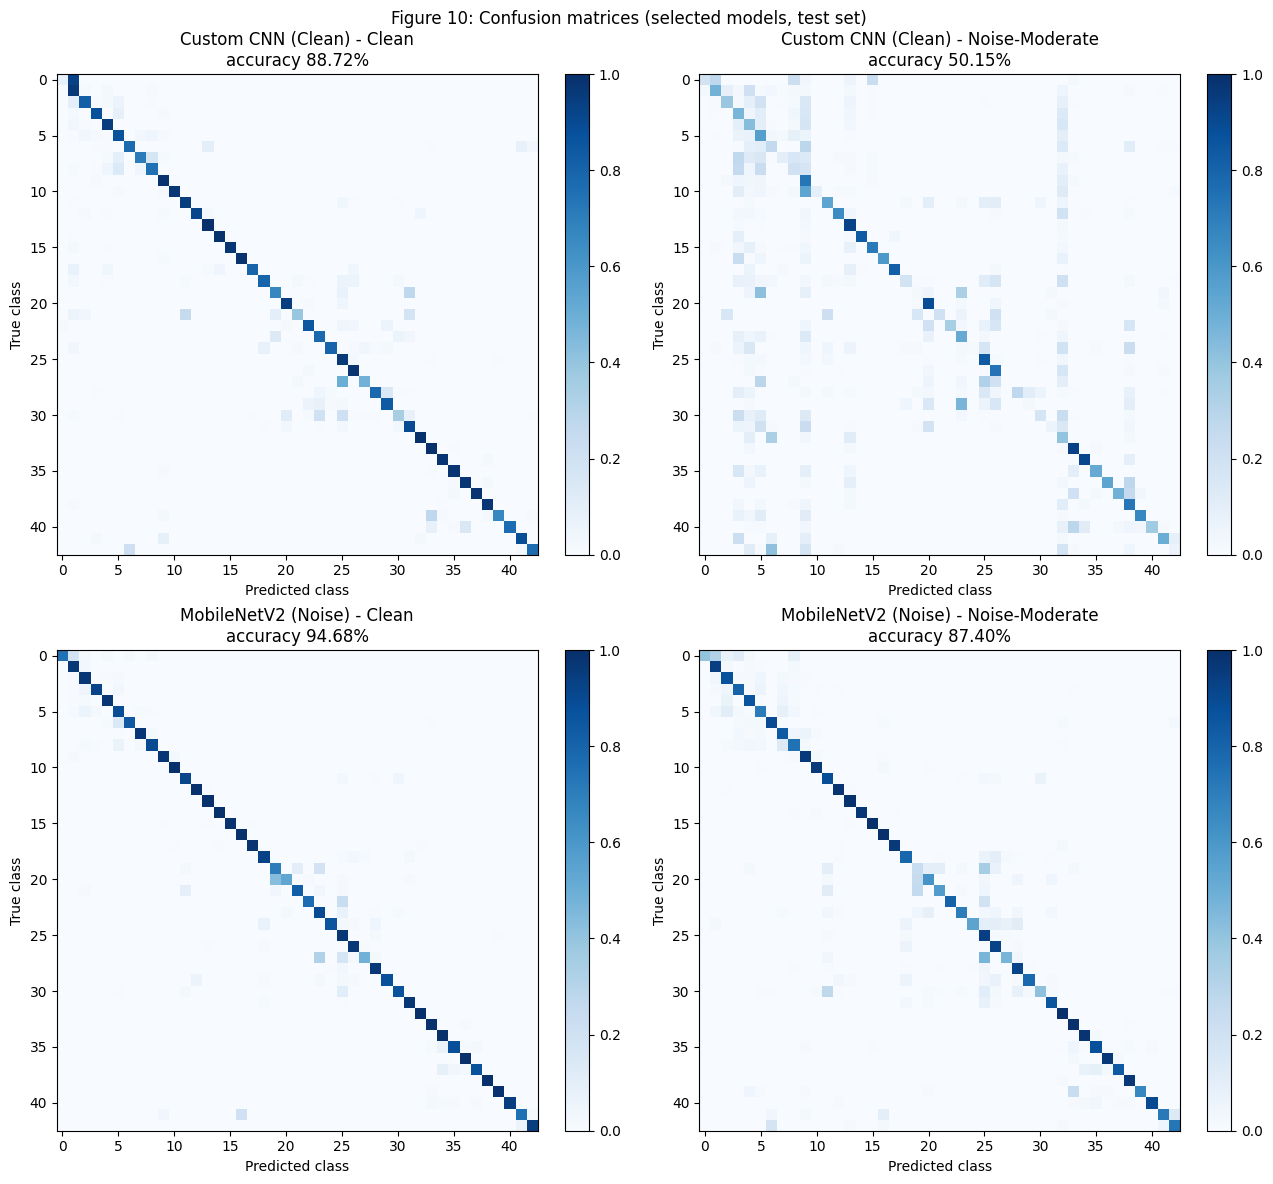

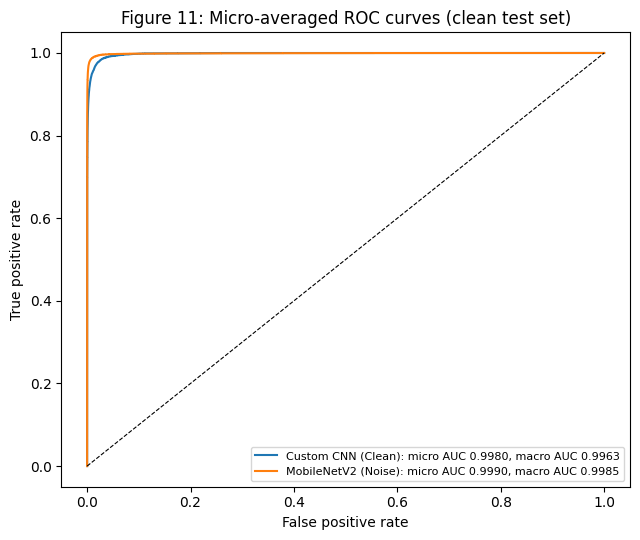

,Architecture,Config,Macro OvR ROC-AUC,Micro ROC-AUC
0,Custom CNN,Clean,0.99630,0.99796
1,MobileNetV2,Noise,0.99853,0.99904


In [ ]:
# best model per architecture, chosen on VALIDATION macro-F1 (clean validation set)
best = {a: max(AUGS, key=lambda g: INFOS[(a, g)]["val_macro_f1"]) for a in ARCHS}
print("Selected (validation macro-F1):", {LABEL[a]: g for a, g in best.items()})

# Figure 10: confusion matrices (clean and moderate noise, row-normalised)
fig, ax = plt.subplots(2, 2, figsize=(13, 12))
for r, arch in enumerate(ARCHS):
    for c, cond in enumerate(["Clean", "Noise-Moderate"]):
        cm = confusion_matrix(y_test, PREDS[(arch, best[arch], cond)], labels=range(NUM_CLASSES)).astype(float)
        im = ax[r, c].imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1); ax[r, c].grid(False)
        ax[r, c].set_title(f"{LABEL[arch]} ({best[arch]}) - {cond}\naccuracy {accuracy_score(y_test, PREDS[(arch, best[arch], cond)]) * 100:.2f}%")
        ax[r, c].set_xlabel("Predicted class"); ax[r, c].set_ylabel("True class"); fig.colorbar(im, ax=ax[r, c], fraction=0.046)
fig.suptitle("Figure 10: Confusion matrices (selected models, test set)")
save_fig(fig, "fig10_confusion_matrices")

# Figure 11: ROC (clean test set, one-vs-rest from softmax probabilities)
fig, ax = plt.subplots(figsize=(6.5, 5.5)); roc_rows = []
y_bin = label_binarize(y_test, classes=list(range(NUM_CLASSES)))
for arch in ARCHS:
    model = load_model(f"{arch}_{best[arch]}", make_cfg(arch, best[arch], LR_MAIN[arch], EPOCHS, IMG_SIZE))
    probs = F.softmax(predict_logits(model, TEST["Clean"]).double(), dim=1).numpy()
    macro_auc = roc_auc_score(y_test, probs, multi_class="ovr", average="macro")
    fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel()); micro_auc = auc(fpr, tpr)
    roc_rows.append({"Architecture": LABEL[arch], "Config": best[arch], "Macro OvR ROC-AUC": macro_auc, "Micro ROC-AUC": micro_auc})
    ax.plot(fpr, tpr, label=f"{LABEL[arch]} ({best[arch]}): micro AUC {micro_auc:.4f}, macro AUC {macro_auc:.4f}")
    del model; torch.cuda.empty_cache()
ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend(loc="lower right", fontsize=8)
ax.set_title("Figure 11: Micro-averaged ROC curves (clean test set)")
save_fig(fig, "fig11_roc")
save_table(pd.DataFrame(roc_rows).round(5), "roc_auc")

## 11. Final Results Summary

In [13]:
final = summ[["Architecture", "Config", "Clean acc (%)", "Mean corrupted acc (%)", "Macro-F1 clean (%)", "Accuracy drop (pp)",
              "Robustness improvement (pp)", "Clean accuracy cost (pp)", "Training time (s)", "Parameters"]].round(2)
save_table(final, "final_summary")
print("Per-condition accuracy (%):")
display(acc.round(2))
print("Files written to", RES_DIR.resolve(), "and", CKPT_DIR.resolve())
print(sorted(p.name for p in (RES_DIR / "tables").glob("*.csv")))
print(sorted(p.name for p in (RES_DIR / "figures").glob("*.png")))

,Architecture,Config,Clean acc (%),Mean corrupted acc (%),Macro-F1 clean (%),Accuracy drop (pp),Robustness improvement (pp),Clean accuracy cost (pp),Training time (s),Parameters
0,Custom CNN,Clean,88.72,74.24,83.60,14.47,0.00,0.00,114.43,629067
1,Custom CNN,Noise,88.90,86.93,82.94,1.97,12.69,-0.18,157.99,629067
2,Custom CNN,Blur,89.95,73.33,84.19,16.62,-0.91,-1.24,259.24,629067
3,Custom CNN,Mixed,88.86,86.88,84.22,1.98,12.64,-0.14,208.52,629067
4,MobileNetV2,Clean,92.98,63.83,88.25,29.16,0.00,0.00,255.04,2278955
5,MobileNetV2,Noise,94.68,92.28,91.42,2.40,28.46,-1.69,300.65,2278955
6,MobileNetV2,Blur,93.87,65.22,89.95,28.65,1.40,-0.89,382.03,2278955
7,MobileNetV2,Mixed,94.89,91.54,91.29,3.35,27.71,-1.90,349.75,2278955


Per-condition accuracy (%):


condition            Blur-Mild  Blur-Moderate  Clean  Noise-Mild  \
architecture config                                                
Custom CNN   Blur        89.89          88.68  89.95       69.08   
             Clean       88.51          86.87  88.72       71.44   
             Mixed       88.81          87.74  88.86       87.21   
             Noise       88.59          87.15  88.90       87.59   
MobileNetV2  Blur        94.22          94.47  93.87       46.50   
             Clean       93.29          91.65  92.98       45.83   
             Mixed       95.15          95.03  94.89       91.21   
             Noise       94.80          94.23  94.68       92.71   

condition            Noise-Moderate  
architecture config                  
Custom CNN   Blur             45.68  
             Clean            50.15  
             Mixed            83.76  
             Noise            84.41  
MobileNetV2  Blur             25.69  
             Clean            24.54  
             Mixed            84.76  
             Noise            87.40

Files written to /content/drive/MyDrive/DL_Project/results and /content/drive/MyDrive/DL_Project/checkpoints
['all_results.csv', 'dataset_summary.csv', 'final_hyperparameters.csv', 'final_summary.csv', 'image_size_statistics.csv', 'lr_search.csv', 'resolution_reduction.csv', 'roc_auc.csv', 'training_summary.csv']
['fig01_class_distribution.png', 'fig01c_sample_images.png', 'fig02_corruption_examples.png', 'fig03_training_curves.png', 'fig04_lr_search.png', 'fig05_resolution_reduction.png', 'fig06_clean_accuracy.png', 'fig07_severity.png', 'fig08_mean_corrupted.png', 'fig09_tradeoff.png', 'fig10_confusion_matrices.png', 'fig11_roc.png']


## 12. Summary of Findings

All numbers come from the final run (test set, one training run per configuration). Accuracy is in %, differences in percentage points (pp). With 12,630 test images, the sampling error of one accuracy near 90 % is about 0.3 pp. Seed-to-seed variation was not measured, so differences of about 1 pp or less should not be read as real effects.

### Research question 1: does mixed augmentation improve robustness while preserving clean accuracy?

Partly. Mixed training clearly improves robustness over clean training, but it does **not** improve on noise-only training, and it does not reduce clean accuracy.

| Architecture | Config | Clean acc | Mean corrupted acc | Robustness improvement | Clean accuracy cost |
|---|---|---|---|---|---|
| Custom CNN | Clean | 88.72 | 74.24 | 0.00 | 0.00 |
| Custom CNN | Noise | 88.90 | 86.93 | +12.69 | -0.18 |
| Custom CNN | Blur | 89.95 | 73.33 | -0.91 | -1.24 |
| Custom CNN | Mixed | 88.86 | 86.88 | +12.64 | -0.14 |
| MobileNetV2 | Clean | 92.98 | 63.83 | 0.00 | 0.00 |
| MobileNetV2 | Noise | 94.68 | 92.28 | +28.46 | -1.69 |
| MobileNetV2 | Blur | 93.87 | 65.22 | +1.40 | -0.89 |
| MobileNetV2 | Mixed | 94.89 | 91.54 | +27.71 | -1.90 |

A negative clean accuracy cost means the augmented model scored higher on clean images than the clean-trained one.

1. **Noise augmentation helps against noise, a lot.** Accuracy under mild / moderate noise rises from 71.4 / 50.2 to 87.6 / 84.4 (custom CNN) and from 45.8 / 24.5 to 92.7 / 87.4 (MobileNetV2).
2. **Blur augmentation gives at most a small gain against blur.** Gains are +1.4 / +1.8 pp (custom CNN) and +0.9 / +2.8 pp (MobileNetV2) for mild / moderate blur. The clean-trained models were barely hurt by blur at these severities (accuracy drop 0.2–1.8 pp for the custom CNN, and 1.3 pp or less for MobileNetV2), so there was little to recover. The blur-trained models were also slightly better on clean images, so the gain cannot be assigned to blur robustness alone. Blur augmentation did not help against noise.
3. **Mixed vs. the single corruptions.** Mixed training roughly matches noise-only training: mean corrupted accuracy 86.88 vs. 86.93 (custom CNN) and 91.54 vs. 92.28 (MobileNetV2). On noise conditions it is slightly lower (by 0.4–0.7 pp for the custom CNN, 1.5–2.6 pp for MobileNetV2). On blur conditions it is about equal to blur-only. Mixed only trains on noise for 25 % of images instead of 50 %, which may explain the small noise deficit; this was not tested. Mixed therefore covers both corruption types without losing much, but the hypothesis that mixing beats the best single corruption is not supported here.
4. **Mixed does not cost clean accuracy.** It scores 88.86 vs. 88.72 (custom CNN) and 94.89 vs. 92.98 (MobileNetV2). The custom CNN difference is within noise. All three augmented MobileNetV2 models beat the clean-trained one by 0.9–1.9 pp, which may be a regularization effect, since the clean model reached about 100 % training accuracy.

### Research question 2: do the architectures behave differently?

- MobileNetV2 is more accurate on clean images (92.98 vs. 88.72) but **more fragile when trained clean**. Its accuracy drop is 29.2 pp on average vs. 14.5 pp for the custom CNN, and under moderate noise it falls to 24.5 % (custom CNN: 50.2 %).
- With noise or mixed augmentation, both models lose only 2–3 pp on average, and MobileNetV2 stays higher in absolute terms (mean corrupted accuracy 91.5–92.3 vs. 86.9).
- Both are nearly insensitive to blur at these severities.
- MobileNetV2 has 3.6x the parameters (2,278,955 vs. 629,067) and took about 2.2x longer to train (255 s vs. 114 s for clean training). The differences are confounded: MobileNetV2 is also pretrained and larger.

### Best overall trade-off

For MobileNetV2, noise and mixed are practically tied. Mixed has the highest clean accuracy (94.89) and the best blur accuracy; noise has the highest mean corrupted accuracy (92.28, +0.74 pp). For the custom CNN the two are tied (88.90 / 86.93 vs. 88.86 / 86.88). If both corruption types matter, mixed is the safer choice; if only noise matters, noise-only is equally good.

### Other experiments

- **Learning rate (custom CNN, 8 epochs, validation):** 1e-3 gave 85.9 %, 3e-4 gave 85.4 %, and 1e-4 gave 77.0 %. 1e-3 was selected, though it is effectively tied with 3e-4.
- **Input resolution (custom CNN, 8 epochs, validation):** 64x64 reached 92.0 % vs. 85.9 % at 96x96, with 56 % fewer input values and 44 % less training time (34 s vs. 61 s). This is unexpected. A possible reason is that GTSRB images are small (median width 43 px), so 96 px mostly upsamples them; this was not tested. The main experiments still use 96x96, as specified, and this was a single run.
- **ROC-AUC (clean test set, selected models):** macro one-vs-rest AUC 0.9963 (custom CNN, Clean) and 0.9985 (MobileNetV2, Noise); micro AUC 0.9980 and 0.9990. AUC is near 1 for both and separates the models less than macro-F1 does.
- **Selected models:** the models in the confusion-matrix and ROC figures were chosen on validation macro-F1: Custom CNN (Clean) and MobileNetV2 (Noise).

### Limitations

- One training seed per configuration, so seed variance is unknown.
- Test corruptions are the same types as the training corruptions, at overlapping strengths. The results do not extend to unseen corruptions such as fog, rain, motion blur or occlusion.
- The corruption severities are proposed settings, not an established benchmark.
- MobileNetV2 was fully fine-tuned with BatchNorm statistics updating. An earlier version with frozen BatchNorm statistics and only the last 3 blocks fine-tuned reached only about 70 % validation accuracy.